# ▓▒░ PIXL :: STAGE 1 :: PRETRAIN ON PHOTOS ░▒▓

Trains the caption-to-image transformer ([`src/model.py`](../src/model.py)) on the photo pairs: caption → 32×32 image of palette tokens. This stage teaches what objects look like, their colours and rough layout; pixel-art style and placement come in stage 2.

| | |
|---|---|
| **Data** | `photos` from Hugging Face ([`src/data.py`](../src/data.py)): 82,651 train pairs, 1,639 test pairs |
| **Model** | 14.8M parameters: 8 layers, width 384, 6 heads |
| **Loss** | Cross-entropy on the 1,024 pixel tokens of each image |
| **Speed** | ~0.8 s per batch of 16 on an Apple-silicon GPU: ~70 minutes per epoch |

**Run the cells in order.** The panel updates every few steps; every `EVAL_EVERY` steps the notebook measures the test loss, draws samples, saves `checkpoints/pretrain.pt` and logs a line. Interrupt any time (■ / Kernel ▸ Interrupt) and run the training cell again to continue from the last checkpoint. Set `QUICK = True` for a two-minute trial run.

In [1]:
import itertools
import math
import os
import sys
import time
from dataclasses import asdict
from pathlib import Path

# Run from the project root, so src/ and its palette and tokenizer files are found.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import torch
from IPython.display import HTML, display
from matplotlib import pyplot as plt
from torch.utils.data import DataLoader

from misc import retro
from src.data import load
from src.model import Config, Pixl, encode_captions
from src.tokenizer import Tokenizer

DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

print(f"device {DEVICE} | torch {torch.__version__}")

device mps | torch 2.14.1


## Settings

The learning rate warms up linearly for `WARMUP` steps, then follows a cosine curve down to `MIN_LR` by the last step. Weight decay applies to weight matrices only, not to biases or norm scales. `CAPTION_DROP` replaces 10% of captions with the empty caption, so the model also learns unconditioned images; sampling uses that for classifier-free guidance.

In [3]:
QUICK = False  # True: a short run that checks every cell works

EPOCHS = 3
BATCH = 16

# LR Schedule 
PEAK_LR = 6e-4
MIN_LR = 6e-5

WARMUP = 500

WEIGHT_DECAY = 0.1
CLIP = 1.0
CAPTION_DROP = 0.1

LOG_EVERY = 10
EVAL_EVERY = 500
TEST_BATCHES = 32
PREVIEW = ["dog", "cat", "tree", "car", "house", "man riding horse", "sailing ship", "pizza"]

SEED = 0

CHECKPOINT = Path("checkpoints/pretrain.pt")
BEST = Path("checkpoints/pretrain-best.pt")
RESUME = True
MAX_STEPS = None  # stop after this many steps; None trains all epochs

if QUICK:
    EPOCHS, WARMUP, LOG_EVERY, EVAL_EVERY, TEST_BATCHES, MAX_STEPS = 1, 20, 5, 30, 2, 60
    CHECKPOINT, BEST = Path("checkpoints/quick.pt"), Path("checkpoints/quick-best.pt")
CHECKPOINT.parent.mkdir(exist_ok=True)

## Data

Every row is a caption and a 32×32 grid of palette tokens; the first load downloads the photos and encodes them once. The preview photos below are the real test images for the `PREVIEW` captions: samples are drawn for the same captions at every evaluation.

train 82,651 photos | test 1,639 | 5,165 steps per epoch | 15,495 steps in total


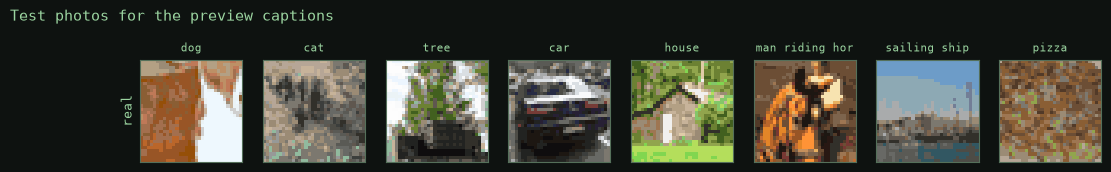

In [4]:
tokenizer = Tokenizer.load()
train_data = load("photos", "train")
test_data = load("photos", "test")
steps_per_epoch = len(train_data) // BATCH
total_steps = MAX_STEPS or EPOCHS * steps_per_epoch
print(
    f"train {len(train_data):,} photos | test {len(test_data):,} | "
    f"{steps_per_epoch:,} steps per epoch | {total_steps:,} steps in total"
)

test_captions = test_data["caption"]
references = np.stack([test_data[test_captions.index(c)]["tokens"].numpy() for c in PREVIEW])
preview_ids = encode_captions(PREVIEW, tokenizer).to(DEVICE)
figure = retro.grid([("real", references)], PREVIEW, "Test photos for the preview captions")
plt.show()

## Model and optimiser

In [5]:
torch.manual_seed(SEED)
model = Pixl(Config()).to(DEVICE)
# weights 
matrices = [p for p in model.parameters() if p.dim() >= 2]
# biases and layer norms 
others = [p for p in model.parameters() if p.dim() < 2]
optimizer = torch.optim.AdamW(
    [
        {"params": matrices, "weight_decay": WEIGHT_DECAY},
        {"params": others, "weight_decay": 0.0},
    ],
    lr=PEAK_LR,
    betas=(0.9, 0.95),
)

def learning_rate(step: int) -> float:
    """Linear warm-up to PEAK_LR, then cosine decay to MIN_LR at the last step."""
    if step < WARMUP:
        return PEAK_LR * (step + 1) / WARMUP
    progress = min(1.0, (step - WARMUP) / max(1, total_steps - WARMUP))
    return MIN_LR + 0.5 * (PEAK_LR - MIN_LR) * (1 + math.cos(math.pi * progress))

print(f"parameters {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M")

parameters 14.8M


## Evaluation, samples and checkpoints

- **Test loss** uses the first `TEST_BATCHES` test batches, always the same photos, so evaluations compare; the full test set runs at the end of each epoch.
- **Samples** use a fixed seed, so changes between evaluations come from training, not chance.
- **Checkpoints**: `CHECKPOINT` holds everything needed to resume; `BEST` holds only the weights with the lowest test loss, which stage 2 starts from.

In [6]:
@torch.no_grad()
def test_loss(batches: int | None) -> float:
    """Mean test loss over the first `batches` test batches, or all of them for None."""
    model.eval()
    total, count = 0.0, 0
    for batch in itertools.islice(DataLoader(test_data, batch_size=BATCH), batches):
        captions = encode_captions(batch["caption"], tokenizer).to(DEVICE)
        pixels = batch["tokens"].flatten(1).to(DEVICE)
        total += model.loss(captions, pixels).item() * len(pixels)
        count += len(pixels)
    model.train()
    return total / count


@torch.no_grad()
def preview() -> torch.Tensor:
    """Samples one image per PREVIEW caption with a fixed seed: (n, 32, 32) uint8."""
    model.eval()
    torch.manual_seed(SEED)  # training draws no torch random numbers, so this is safe
    images = model.generate(preview_ids, top_k=32)
    model.train()
    return images.view(-1, 32, 32).to(torch.uint8).cpu()


def save_checkpoint() -> None:
    state = {
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "step": step,
        "train_log": train_log,
        "test_log": test_log,
        "snapshots": snapshots,
        "best": best,
    }
    torch.save(state, CHECKPOINT)


def save_best(loss: float) -> None:
    torch.save({"model": model.state_dict(), "config": asdict(model.config), "step": step, "test_loss": loss}, BEST)

## Live display

The panel updates in place; log lines stay below it as a record; the dashboard redraws at every evaluation.

In [7]:
def status(epoch: int, recent_steps: list[float]) -> str:
    """Builds the live panel from the latest logs."""
    seconds = sum(recent_steps) / max(1, len(recent_steps))
    losses = [p["loss"] for p in train_log]
    trend = "▼" if len(losses) > 1 and losses[-1] < losses[-2] else "▲" if len(losses) > 1 else " "
    last_test = f"{test_log[-1]['loss']:.3f}" if test_log else "-----"
    best_test = f"{best:.3f}" if best < float("inf") else "-----"
    lines = [
        f"epoch {epoch + 1}/{EPOCHS}   step {step:,}/{total_steps:,}   {step / total_steps:6.1%}",
        retro.bar(step / total_steps, 62),
        "",
        f"loss  {losses[-1] if losses else 0:6.3f} {trend}   test {last_test}   best {best_test}",
        f"lr    {learning_rate(max(step - 1, 0)):.2e}   speed {BATCH * 1056 / max(seconds, 1e-9):,.0f} tok/s",
        f"time  {retro.clock(time.time() - started)}   left {retro.clock((total_steps - step) * seconds)}",
        "",
        f"trend {retro.sparkline(losses, 56)}",
    ]
    return retro.panel("stage 1: pretrain", lines)


def evaluate(epoch_end: bool) -> None:
    """Tests, samples, saves, logs a line and redraws the dashboard."""
    global best
    loss = test_loss(TEST_BATCHES)
    test_log.append({"step": step, "loss": loss})
    images = preview()
    snapshots.append((step, images))
    improved = loss < best
    if improved:
        best = loss
        save_best(loss)
    save_checkpoint()
    fields = {
        "time": retro.clock(time.time() - started),
        "epoch": f"{step // steps_per_epoch + (0 if epoch_end else 1)}/{EPOCHS}",
        "step": f"{step:,}",
        "loss": f"{train_log[-1]['loss']:.3f}" if train_log else "-",
        "test": f"{loss:.3f}",
        "lr": f"{learning_rate(step - 1):.1e}",
    }
    if epoch_end:
        fields["full test"] = f"{test_loss(None):.3f}"
    print(retro.log_line(fields, highlight=improved))
    figure = retro.dashboard(
        train_log, test_log, images.numpy(), references, PREVIEW, f"Stage 1: step {step:,}"
    )
    board.update(figure)
    plt.close(figure)

## Train

Each epoch shuffles the photos in a fixed order (seeded by the epoch number), so a resumed run skips exactly the batches already trained on.

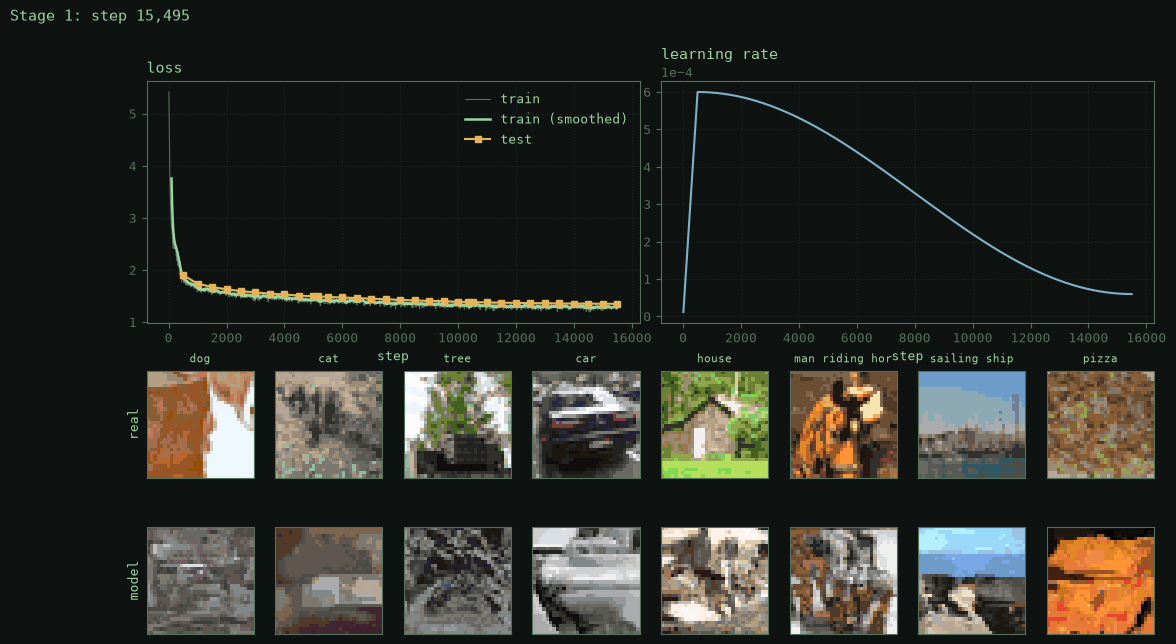

time 0:08:01 │ epoch 1/3 │ step 500 │ loss 1.864 │ test 1.903 │ lr 6.0e-04  best
time 0:15:41 │ epoch 1/3 │ step 1,000 │ loss 1.601 │ test 1.739 │ lr 6.0e-04  best
time 0:23:35 │ epoch 1/3 │ step 1,500 │ loss 1.635 │ test 1.676 │ lr 5.9e-04  best
time 0:31:03 │ epoch 1/3 │ step 2,000 │ loss 1.636 │ test 1.632 │ lr 5.9e-04  best
time 0:38:29 │ epoch 1/3 │ step 2,500 │ loss 1.460 │ test 1.597 │ lr 5.8e-04  best
time 0:45:54 │ epoch 1/3 │ step 3,000 │ loss 1.539 │ test 1.571 │ lr 5.6e-04  best
time 0:53:19 │ epoch 1/3 │ step 3,500 │ loss 1.512 │ test 1.549 │ lr 5.5e-04  best
time 1:00:43 │ epoch 1/3 │ step 4,000 │ loss 1.420 │ test 1.532 │ lr 5.3e-04  best
time 1:08:06 │ epoch 1/3 │ step 4,500 │ loss 1.445 │ test 1.511 │ lr 5.1e-04  best
time 1:15:31 │ epoch 1/3 │ step 5,000 │ loss 1.499 │ test 1.497 │ lr 4.9e-04  best
time 1:18:03 │ epoch 1/3 │ step 5,165 │ loss 1.391 │ test 1.495 │ lr 4.8e-04 │ full test 1.431  best
time 1:23:21 │ epoch 2/3 │ step 5,500 │ loss 1.351 │ test 1.485 │ lr 4.

In [8]:
train_log: list[dict[str, float]] = []
test_log: list[dict[str, float]] = []
snapshots: list[tuple[int, torch.Tensor]] = []
best = float("inf")
step = 0
if RESUME and CHECKPOINT.exists():
    state = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=True)
    model.load_state_dict(state["model"])
    optimizer.load_state_dict(state["optimizer"])
    step, train_log, test_log = state["step"], state["train_log"], state["test_log"]
    snapshots, best = state["snapshots"], state["best"]
    print(f"resumed from {CHECKPOINT} at step {step:,}")

panel = display(HTML(""), display_id=True)
board = display(HTML(""), display_id=True)
started, recent_steps, window = time.time(), [], []
epoch = step // steps_per_epoch
model.train()
try:
    while step < total_steps:
        epoch = step // steps_per_epoch
        order = torch.randperm(len(train_data), generator=torch.Generator().manual_seed(SEED + epoch))
        skip = (step - epoch * steps_per_epoch) * BATCH
        batches = DataLoader(train_data, batch_size=BATCH, sampler=order[skip:].tolist(), drop_last=True)
        for batch in batches:
            tick = time.time()
            for group in optimizer.param_groups:
                group["lr"] = learning_rate(step)
            captions = encode_captions(batch["caption"], tokenizer, drop=CAPTION_DROP).to(DEVICE)
            pixels = batch["tokens"].flatten(1).to(DEVICE)
            loss = model.loss(captions, pixels)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP)
            optimizer.step()
            window.append(loss.item())
            step += 1
            recent_steps = (recent_steps + [time.time() - tick])[-50:]

            if step % LOG_EVERY == 0:
                train_log.append({"step": step, "loss": sum(window) / len(window), "lr": learning_rate(step - 1)})
                window = []
                panel.update(HTML(status(epoch, recent_steps)))
            epoch_end = step % steps_per_epoch == 0
            if step % EVAL_EVERY == 0 or epoch_end or step == total_steps:
                evaluate(epoch_end)
            if epoch_end or step >= total_steps:
                break
    panel.update(HTML(status(min(epoch, EPOCHS - 1), recent_steps)))
    print(retro.log_line({"done": f"{step:,} steps", "best test": f"{best:.3f}", "saved": str(BEST)}))
except KeyboardInterrupt:
    last = test_log[-1]["step"] if test_log else 0
    print(retro.log_line({"stopped": f"step {step:,}", "last checkpoint": f"step {last:,}", "resume": "run this cell again"}))

## Results

How the samples for each preview caption changed, one column per evaluation:

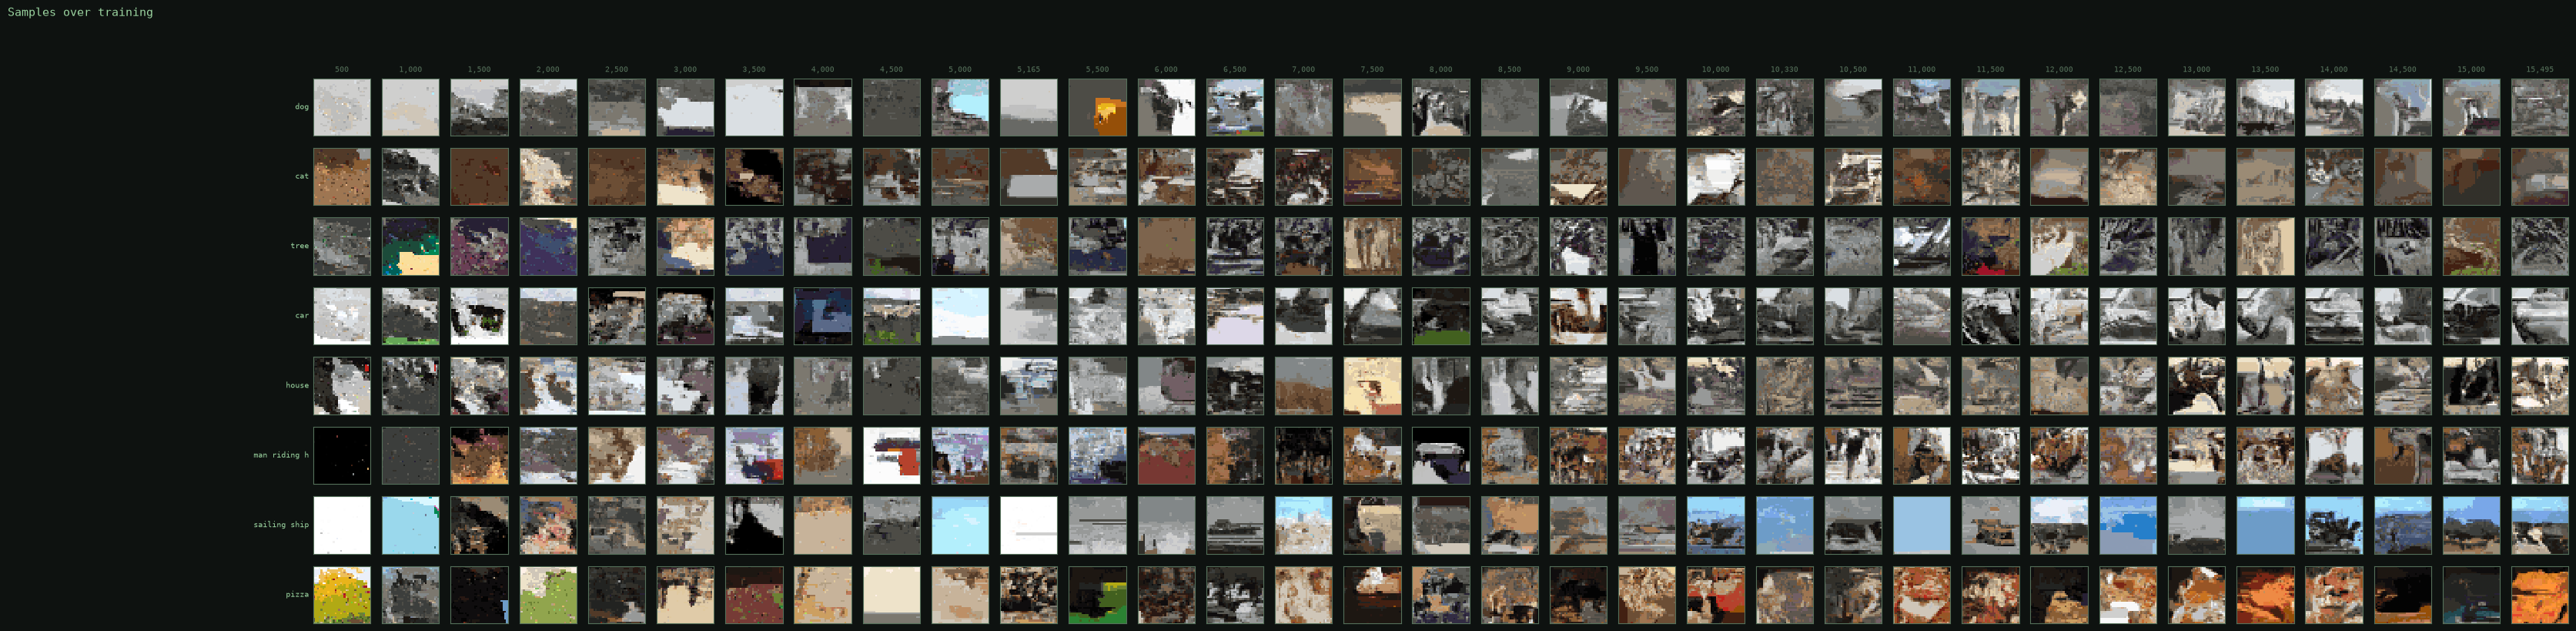

In [9]:
figure = retro.filmstrip([(s, images.numpy()) for s, images in snapshots], PREVIEW)
plt.show()

Samples from the best weights at different guidance scales. Guidance above 1 pushes each image towards what its caption specifically asks for, at twice the cost per step. Edit `PROMPTS` to try your own captions; words outside the training captions still work but were never learned.

best weights: step 15,495, test loss 1.353


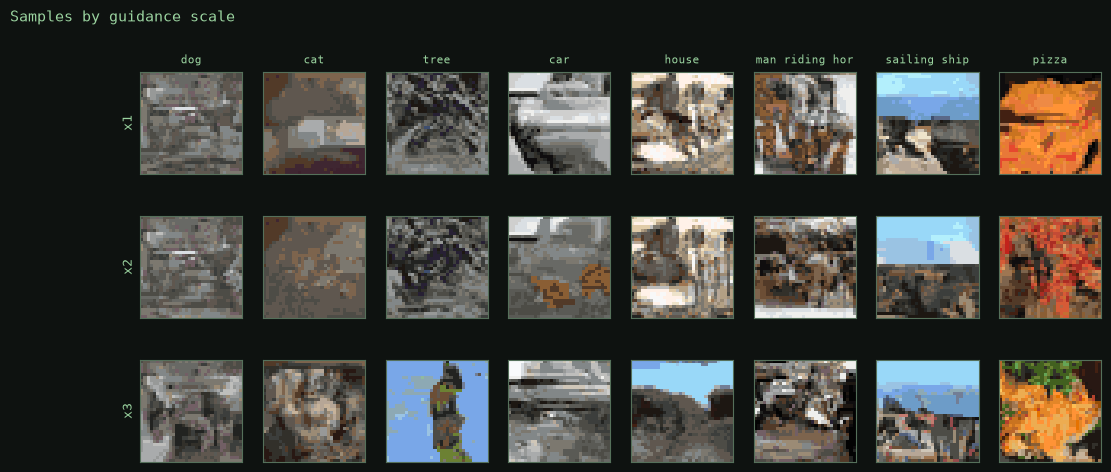

In [10]:
PROMPTS = PREVIEW
best_state = torch.load(BEST, map_location=DEVICE, weights_only=True)
model.load_state_dict(best_state["model"])
model.eval()
ids = encode_captions(PROMPTS, tokenizer).to(DEVICE)
rows = []
for guidance in (1.0, 2.0, 3.0):
    torch.manual_seed(SEED)
    rows.append((f"x{guidance:g}", model.generate(ids, top_k=32, guidance=guidance).view(-1, 32, 32).cpu().numpy()))
print(f"best weights: step {best_state['step']:,}, test loss {best_state['test_loss']:.3f}")
figure = retro.grid(rows, PROMPTS, "Samples by guidance scale")
plt.show()